In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/KTFGHU14.csv", sep=";")
df.head()

,LocalId,GlobalId,Age,Gender,Region,CityCode,TotalSpent,TotalPur,FirstPur,LastPur,NovelPur,ChildPur,YouthPur,CookPur,DiyPur,RefPur,ArtPur,GeogPur,ProvCook,ProvAtlas,ProvArt,RelPur,ProvPur
0,1,25,56.0,0,SW,M,297,5,16/07/2012,14,3,0,1,1,0,0,0,0,0,0,0,0,No
1,2,29,23.0,1,NE,S,128,4,13/07/2013,8,2,0,0,0,0,0,0,0,0,0,0,0,No
2,3,46,61.0,0,NE,D,138,10,04/09/2009,22,3,2,1,2,0,1,0,1,1,0,0,2,No
3,4,47,30.0,0,SW,G,228,2,09/03/2014,2,1,0,0,0,0,0,0,0,0,0,0,0,No
4,5,51,NaN,0,SE,C,257,3,09/07/2013,10,2,0,0,0,0,0,0,0,0,0,0,0,No


### Chargement des données
Les données sont bien chargées : 4 000 lignes et 23 colonnes.
On remarque dès les premières lignes une valeur manquante (NaN)
dans `Age` (client n°5). Elle sera traitée lors du nettoyage (S3).

### 1. Numrique 

In [39]:
# Nature réelle de chaque variable (≠ son encodage dans le fichier)
nature = {
    "LocalId":    ("identifiant", "numéro unique dans l'échantillon, ne décrit pas le client → à supprimer"),
    "GlobalId":   ("identifiant", "numéro unique dans la base complète → à supprimer"),
    "Age":        ("numérique continue", "un âge se compare et se calcule (30 > 20)"),
    "Gender":     ("catégorielle (2 valeurs)", "codé 0/1 mais aucun ordre entre femme et homme"),
    "Region":     ("catégorielle", "4 régions sans ordre (NE n'est pas « plus » que SW)"),
    "CityCode":   ("catégorielle", "19 villes (lettres A à S), sans ordre"),
    "TotalSpent": ("numérique continue", "une somme d'argent"),
    "TotalPur":   ("numérique (comptage)", "nombre de livres achetés"),
    "FirstPur":   ("date", "écrite comme du texte → à convertir en nombre (ancienneté)"),
    "LastPur":    ("numérique (durée)", "nombre de mois depuis le dernier achat"),
    "NovelPur":   ("numérique (comptage)", "nombre de romans achetés"),
    "ChildPur":   ("numérique (comptage)", "nombre de livres pour enfants"),
    "YouthPur":   ("numérique (comptage)", "nombre de livres pour ados"),
    "CookPur":    ("numérique (comptage)", "nombre de livres de cuisine"),
    "DiyPur":     ("numérique (comptage)", "nombre de livres de bricolage"),
    "RefPur":     ("numérique (comptage)", "nombre de dictionnaires/encyclopédies"),
    "ArtPur":     ("numérique (comptage)", "nombre de livres d'art"),
    "GeogPur":    ("numérique (comptage)", "nombre de livres de géographie"),
    "ProvCook":   ("numérique (comptage)", "nombre d'achats du livre de cuisine provençale"),
    "ProvAtlas":  ("numérique (comptage)", "nombre d'achats de l'atlas de la Provence"),
    "ProvArt":    ("numérique (comptage)", "nombre d'achats du livre sur l'art provençal"),
    "RelPur":     ("numérique (comptage)", "nombre de livres liés à l'art en Provence"),
    "ProvPur":    ("catégorielle (2 valeurs) – CIBLE", "Yes/No : c'est la variable à prédire"),
}

tableau_nature = pd.DataFrame({
    "encodage (dans le fichier)": df.dtypes.astype(str),
    "nb de valeurs distinctes": df.nunique(),
    "nature réelle": [nature[c][0] for c in df.columns],
    "justification": [nature[c][1] for c in df.columns],
})
tableau_nature

,encodage (dans le fichier),nb de valeurs distinctes,nature réelle,justification
LocalId,int64,4000,identifiant,"numéro unique dans l'échantillon, ne décrit pa..."
GlobalId,int64,4000,identifiant,numéro unique dans la base complète → à supprimer
Age,float64,72,numérique continue,un âge se compare et se calcule (30 > 20)
Gender,int64,2,catégorielle (2 valeurs),codé 0/1 mais aucun ordre entre femme et homme
Region,str,4,catégorielle,4 régions sans ordre (NE n'est pas « plus » qu...
CityCode,str,19,catégorielle,"19 villes (lettres A à S), sans ordre"
TotalSpent,int64,446,numérique continue,une somme d'argent
TotalPur,int64,20,numérique (comptage),nombre de livres achetés
FirstPur,str,968,date,écrite comme du texte → à convertir en nombre ...
LastPur,int64,18,numérique (durée),nombre de mois depuis le dernier achat


In [22]:
df.isna().sum()

LocalId         0
GlobalId        0
Age           173
Gender          0
Region          0
CityCode       97
TotalSpent      0
TotalPur        0
FirstPur        0
LastPur         0
NovelPur        0
ChildPur        0
YouthPur        0
CookPur         0
DiyPur          0
RefPur          0
ArtPur          0
GeogPur         0
ProvCook        0
ProvAtlas       0
ProvArt         0
RelPur          0
ProvPur         0
dtype: int64

In [23]:
df.nunique()

LocalId       4000
GlobalId      4000
Age             72
Gender           2
Region           4
CityCode        19
TotalSpent     446
TotalPur        20
FirstPur       968
LastPur         18
NovelPur        11
ChildPur         8
YouthPur         6
CookPur          8
DiyPur           6
RefPur           5
ArtPur           6
GeogPur          7
ProvCook         4
ProvAtlas        3
ProvArt          3
RelPur           9
ProvPur          2
dtype: int64

In [40]:
var_num = ["Age", "TotalSpent", "TotalPur", "LastPur",
           "NovelPur", "ChildPur", "YouthPur", "CookPur", "DiyPur", "RefPur",
           "ArtPur", "GeogPur", "ProvCook", "ProvAtlas", "ProvArt", "RelPur"]

stats = df[var_num].describe().T

IQR = stats["75%"] - stats["25%"]
borne_basse = stats["25%"] - 1.5 * IQR
borne_haute = stats["75%"] + 1.5 * IQR

stats["nb_aberrantes"] = [((df[c] < borne_basse[c]) | (df[c] > borne_haute[c])).sum() for c in var_num]
stats["% aberrantes"] = (stats["nb_aberrantes"] / len(df) * 100).round(1)

stats

,count,mean,std,min,25%,50%,75%,max,nb_aberrantes,% aberrantes
Age,3827.0,44.645937,16.003261,12.0,31.0,48.0,58.0,87.0,0,0.0
TotalSpent,4000.0,208.091500,100.948548,15.0,129.0,208.0,283.0,479.0,0,0.0
TotalPur,4000.0,6.253250,4.542606,1.0,3.0,4.0,9.0,20.0,22,0.5
LastPur,4000.0,13.390500,8.103822,2.0,8.0,12.0,16.0,36.0,312,7.8
NovelPur,4000.0,2.420000,1.540517,0.0,1.0,2.0,3.0,10.0,47,1.2
ChildPur,4000.0,0.639750,0.994343,0.0,0.0,0.0,1.0,7.0,232,5.8
YouthPur,4000.0,0.304750,0.611940,0.0,0.0,0.0,0.0,5.0,953,23.8
CookPur,4000.0,0.731250,1.089413,0.0,0.0,0.0,1.0,7.0,334,8.4
DiyPur,4000.0,0.350750,0.687999,0.0,0.0,0.0,1.0,5.0,70,1.8
RefPur,4000.0,0.256250,0.558269,0.0,0.0,0.0,0.0,4.0,819,20.5


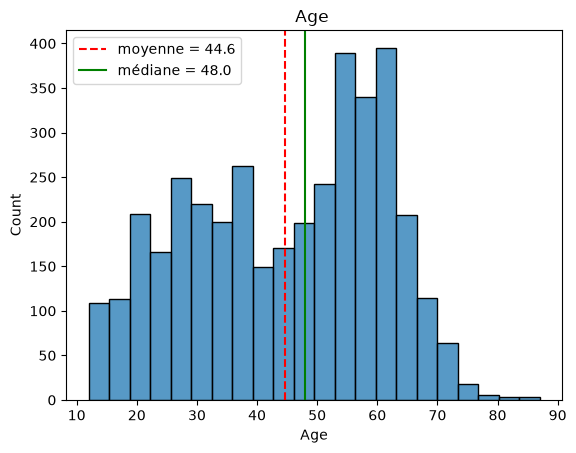

In [33]:
s = df["Age"]
nb_nan = s.isna().sum()

sns.histplot(s)
plt.axvline(s.mean(), color="red", linestyle="--", label=f"moyenne = {s.mean():.1f}")
plt.axvline(s.median(), color="green", label=f"médiane = {s.median():.1f}")
plt.legend()
plt.title(f"Age ")
plt.savefig("figures/hist_Age.png")
plt.show()

**Ce qu'on voit :**
- Il y a deux groupes de clients : des jeunes (20-40 ans) et des plus âgés (50-65 ans). Le groupe des plus âgés est le plus nombreux.
- Entre les deux, vers 40-45 ans, il y a moins de clients.

**Ce que ça veut dire :**
- La moyenne tombe entre les deux groupes, là où il y a peu de clients. Elle ne décrit donc pas bien l'âge des clients.

**Problèmes à noter :**
- Certains clients ont environ 12 ans : c'est jeune, il faudra vérifier si c'est possible.

### 2. TotalSpent

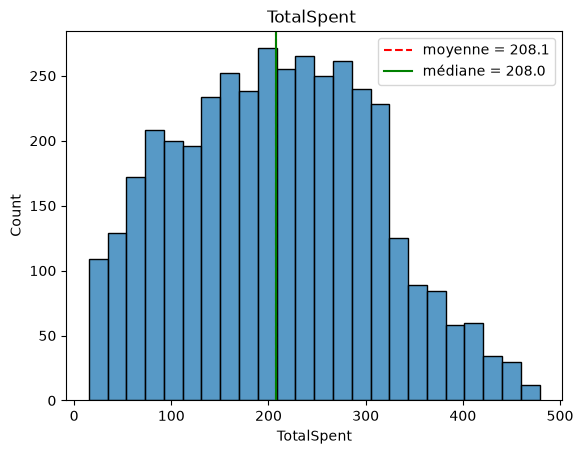

In [34]:
col = "TotalSpent"
s = df[col]
nb_nan = s.isna().sum()

sns.histplot(s)
plt.axvline(s.mean(), color="red", linestyle="--", label=f"moyenne = {s.mean():.1f}")
plt.axvline(s.median(), color="green", label=f"médiane = {s.median():.1f}")
plt.legend()
plt.title(f"{col} ")
plt.savefig(f"figures/hist_{col}.png")
plt.show()

Ce qu'on voit :
- La plupart des clients ont dépensé entre 150 et 320.
- Peu de clients ont dépensé très peu (moins de 50) ou beaucoup (plus de 400).
- La moyenne (208,1) et la médiane (208,0) sont presque égales.

Ce que ça veut dire :
- Les valeurs sont bien réparties des deux côtés du centre. La moyenne décrit bien ce que dépense un client « typique ».

Problèmes à noter :
- Aucun 

### 3. Comptages d'achats

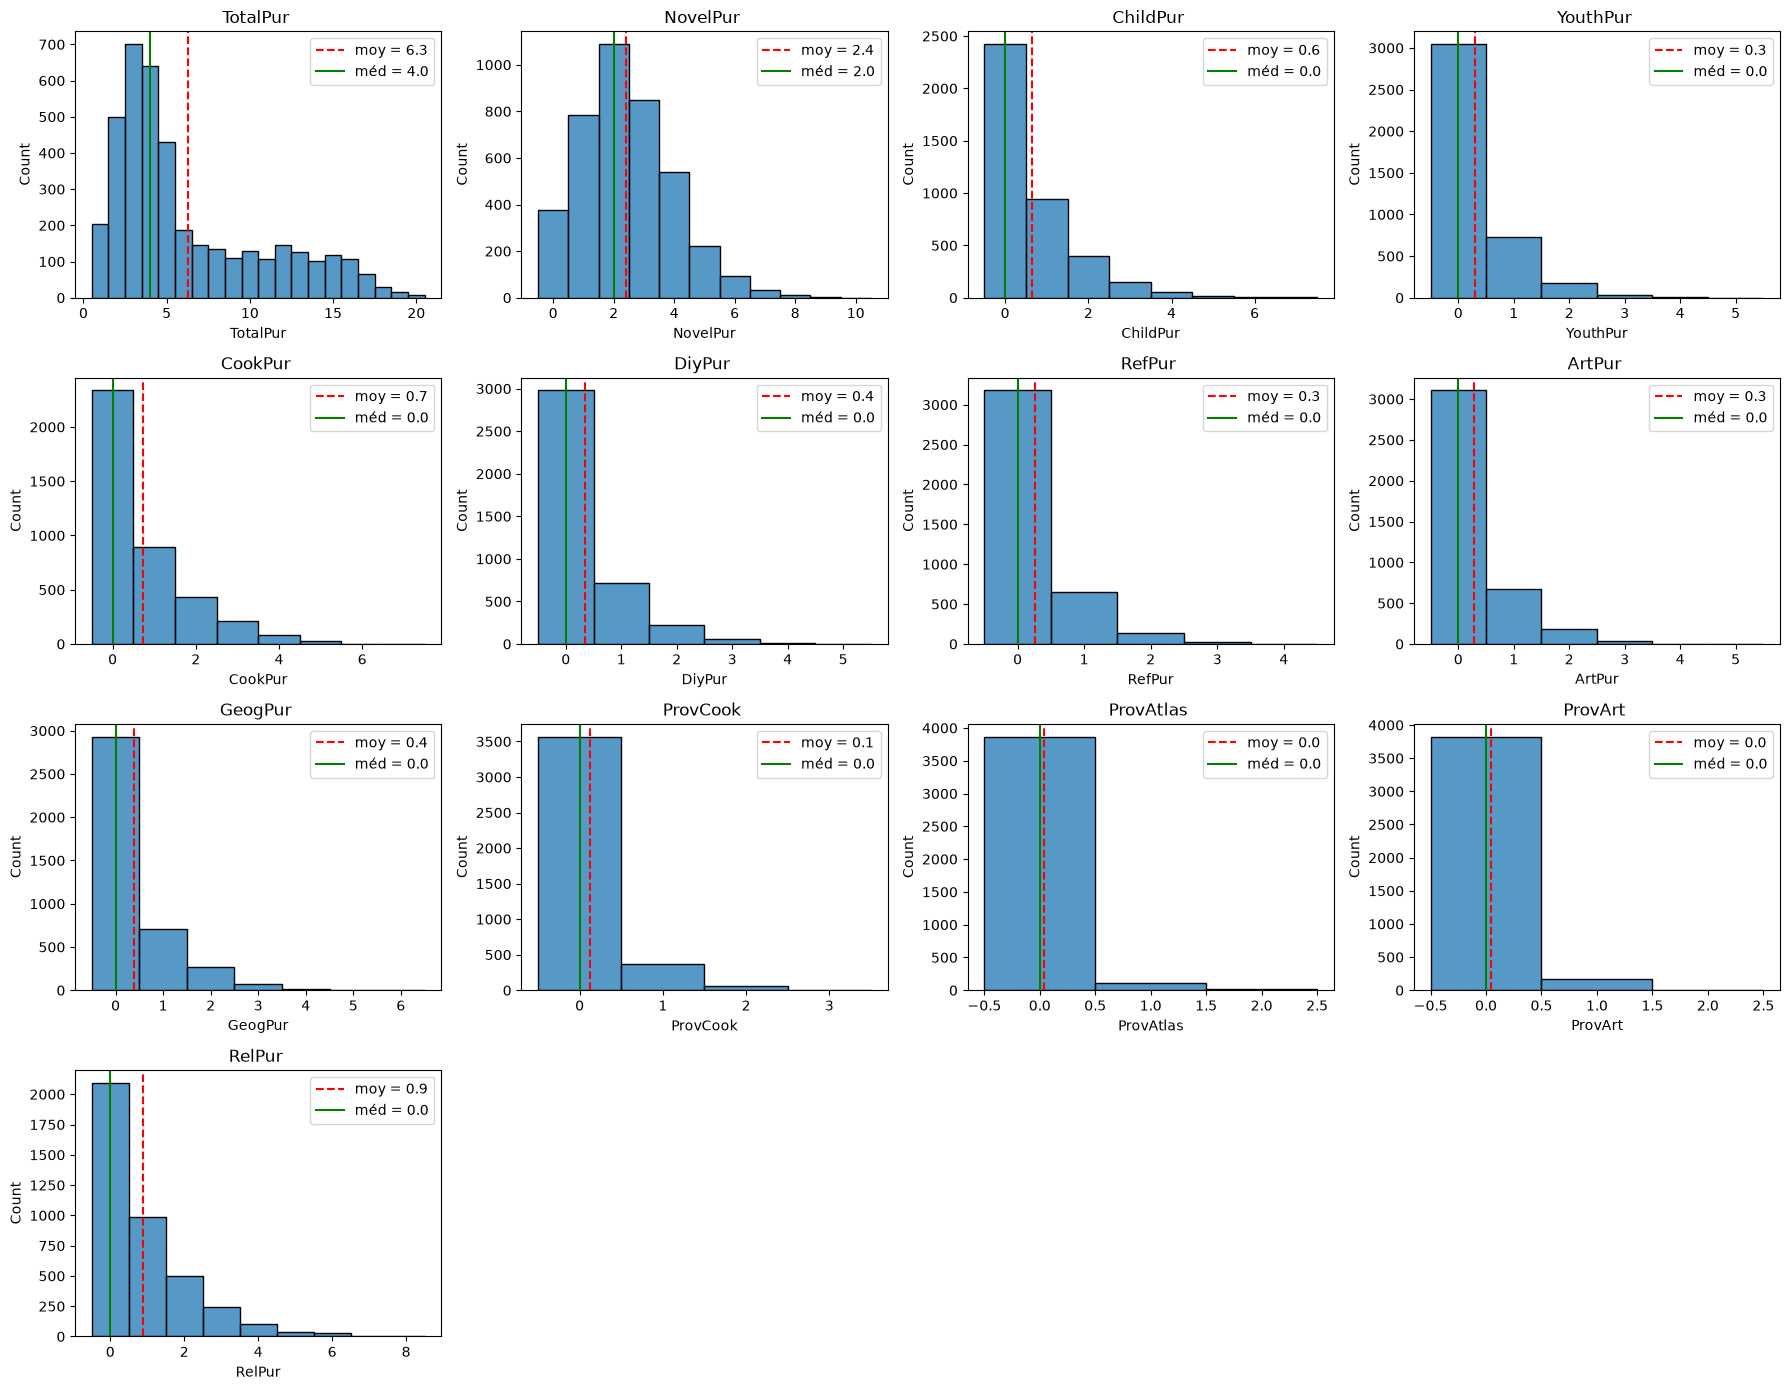

In [35]:
comptages = ["TotalPur", "NovelPur", "ChildPur", "YouthPur", "CookPur", "DiyPur",
             "RefPur", "ArtPur", "GeogPur", "ProvCook", "ProvAtlas", "ProvArt", "RelPur"]

fig, axes = plt.subplots(4, 4, figsize=(18, 14))

for ax, col in zip(axes.flat, comptages):
    s = df[col]
    nb_nan = s.isna().sum()
    pct_zero = (s == 0).mean() * 100

    sns.histplot(s, discrete=True, ax=ax)
    ax.axvline(s.mean(), color="red", linestyle="--", label=f"moy = {s.mean():.1f}")
    ax.axvline(s.median(), color="green", label=f"méd = {s.median():.1f}")
    ax.legend()
    ax.set_title(f"{col} ")

for ax in axes.flat[len(comptages):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig("figures/hist_comptages.png")
plt.show()

Ce qu'on voit :
- TotalPur : tous les clients ont acheté au moins 1 livre. Il y a un pic entre 2 et 5 livres, puis un plateau entre 6 et 17 livres. On dirait deux groupes : des petits et des gros acheteurs.
- NovelPur : presque tous les clients achètent des romans (seulement 9 % à 0). C'est la catégorie la plus achetée.
- Autres catégories (enfants, ados, cuisine, bricolage, dictionnaires, art, géographie) : entre 58 % et 80 % des clients n'ont rien acheté. La plupart des valeurs sont 0, puis il y a de moins en moins de clients quand le nombre augmente.
- Livres sur la Provence (ProvCook, ProvAtlas, ProvArt) : presque personne ne les a achetés (89 % à 97 % de 0).
- RelPur : environ la moitié des clients ont acheté au moins un livre lié à l'art en Provence.

Ce que ça veut dire :
- Pour la plupart de ces variables, la médiane est 0 : la moyenne ne décrit pas bien un client « typique ».
- Les livres sur la Provence sont rares, mais ils pourraient être très utiles pour prédire l'achat du nouveau livre (à vérifier en S2).

Problèmes à noter :
- Aucune valeur manquante, aucune valeur négative.
- TotalPur : deux groupes possibles, à comparer avec l'âge en S2.
- RelPur ne correspond pas à la somme de ProvCook + ProvAtlas + ProvArt : à vérifier.
- ProvAtlas et ProvArt valent presque toujours 0 : ils apportent peu d'information seuls, il faudra peut-être les regrouper.

### 4. Dates (FirstPur et LastPur)

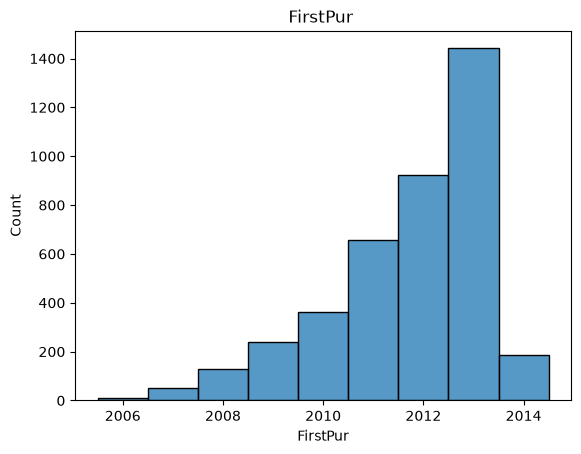

Premier achat le plus ancien : 2006-02-27 00:00:00
Premier achat le plus récent : 2014-03-28 00:00:00
Dates après le 1er mai 2014 (impossible) : 0


In [36]:
# convertir le texte "16/07/2012" en vraie date
dates = pd.to_datetime(df["FirstPur"], format="%d/%m/%Y")
nb_nan = dates.isna().sum()

sns.histplot(dates.dt.year, discrete=True)
plt.title(f"FirstPur ")
plt.savefig("figures/hist_FirstPur.png")
plt.show()

print("Premier achat le plus ancien :", dates.min())
print("Premier achat le plus récent :", dates.max())
print("Dates après le 1er mai 2014 (impossible) :", (dates > "2014-05-01").sum())

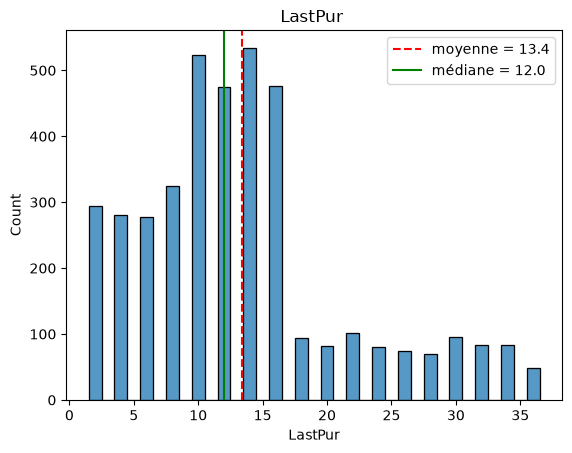

In [37]:
col = "LastPur"
s = df[col]
nb_nan = s.isna().sum()

sns.histplot(s, discrete=True)
plt.axvline(s.mean(), color="red", linestyle="--", label=f"moyenne = {s.mean():.1f}")
plt.axvline(s.median(), color="green", label=f"médiane = {s.median():.1f}")
plt.legend()
plt.title(f"{col} ")
plt.savefig(f"figures/hist_{col}.png")
plt.show()

Ce qu'on voit :
- FirstPur : les premiers achats vont de 2006 à 2014. Le nombre de nouveaux clients augmente chaque année, avec un maximum en 2013.
- 2014 a peu de clients, mais c'est normal : les données s'arrêtent au 1er mai 2014, donc 2014 ne compte que 4 mois.
- LastPur : les valeurs vont de 2 à 36 mois. La plupart des clients ont acheté il y a moins de 16 mois. Après 18 mois, il y a beaucoup moins de clients.
- LastPur ne contient que des nombres pairs (2, 4, 6…).

Ce que ça veut dire :
- La librairie gagne de plus en plus de clients : la plupart sont récents.
- Il y a deux groupes : des clients actifs (achat récent) et des clients inactifs (pas d'achat depuis plus de 18 mois).
- LastPur semble arrondi par tranches de 2 mois : il est moins précis qu'il n'y paraît.

Problèmes à noter :
- Aucune valeur manquante, aucune valeur négative.
- FirstPur est un texte : il faudra le transformer en nombre (par exemple l'ancienneté en mois) en S3.
- LastPur : valeurs uniquement paires, à signaler.
- À vérifier : le dernier achat ne doit pas être plus ancien que le premier achat.

### 5. Variables catégorielles

In [30]:
var_cat = ["Gender", "Region", "CityCode", "ProvPur"]

for c in var_cat:
    freq = pd.DataFrame({
        "effectif": df[c].value_counts(dropna=False),
        "%": (df[c].value_counts(dropna=False, normalize=True) * 100).round(1),
    })
    display(freq)

,effectif,%
Gender,,
0,2818,70.4
1,1182,29.6


,effectif,%
Region,,
NE,1657,41.4
SW,1270,31.8
SE,845,21.1
NW,228,5.7


,effectif,%
CityCode,,
M,234,5.9
N,224,5.6
I,223,5.6
C,219,5.5
L,219,5.5
F,216,5.4
H,213,5.3
S,209,5.2
E,206,5.1


,effectif,%
ProvPur,,
No,3662,91.6
Yes,338,8.5


In [31]:
var_cat = ["Gender", "Region", "CityCode", "ProvPur"]

resume_cat = pd.DataFrame({
    "nb_modalites": df[var_cat].nunique(),
    "mode": df[var_cat].mode().iloc[0],
    "% du mode": [round(df[c].value_counts(normalize=True).iloc[0] * 100, 1) for c in var_cat],
    "modalite_rare": [df[c].value_counts().idxmin() for c in var_cat],
    "% rare": [round(df[c].value_counts(normalize=True).iloc[-1] * 100, 1) for c in var_cat],
    "manquants": df[var_cat].isna().sum(),
})
resume_cat

,nb_modalites,mode,% du mode,modalite_rare,% rare,manquants
Gender,2,0,70.4,1,29.6,0
Region,4,NE,41.4,NW,5.7,0
CityCode,19,M,6.0,K,4.3,97
ProvPur,2,No,91.6,Yes,8.5,0


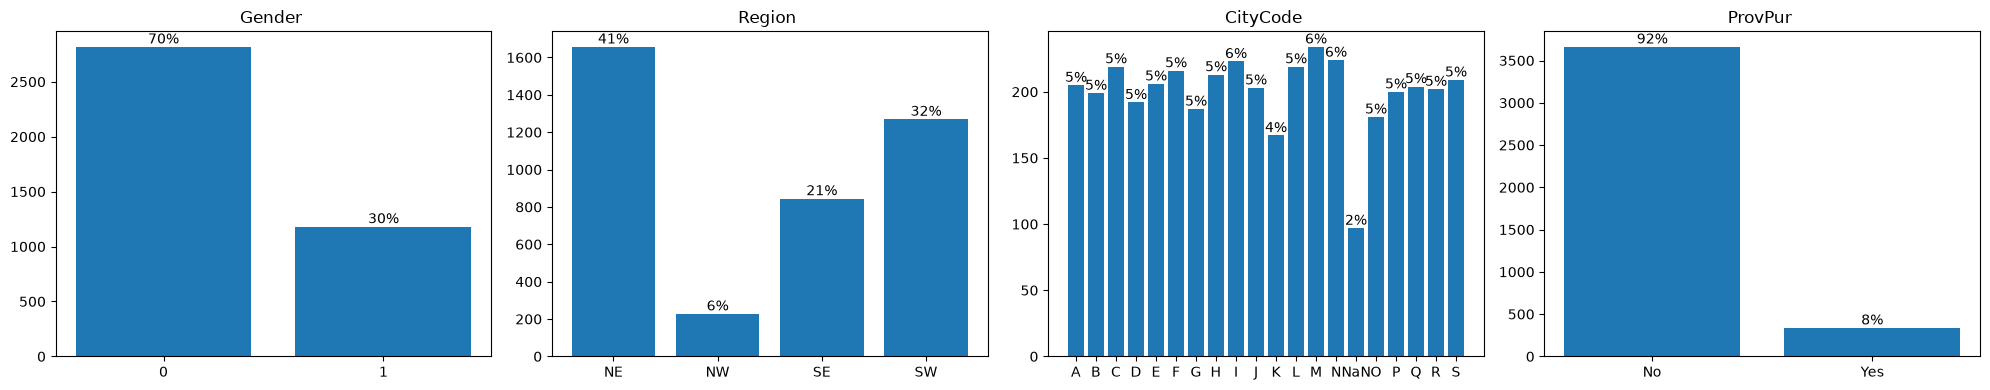

In [38]:
categorielles = ["Gender", "Region", "CityCode", "ProvPur"]

fig, axes = plt.subplots(1, 4, figsize=(20, 4))

for ax, col in zip(axes, categorielles):
    valeurs = df[col].astype("object").fillna("NaN").astype(str)
    comptes = valeurs.value_counts().sort_index()
    pourcentages = comptes / len(df) * 100

    ax.bar(list(comptes.index), comptes.values)
    ax.set_title(f"{col} ")
    for i, p in enumerate(pourcentages):
        ax.text(i, comptes.values[i], f"{p:.0f}%", ha="center", va="bottom")

plt.tight_layout()
plt.savefig("figures/barres_categorielles.png")
plt.show()

Ce qu'on voit :
- Gender : 70 % de femmes (0) et 30 % d'hommes (1).
- Region : les régions ne sont pas équilibrées. NE 41 %, SW 32 %, SE 21 %, et NW seulement 6 %.
- CityCode : les 19 villes (A à S) ont chacune environ 5 % des clients. 97 valeurs manquantes (2 %).
- ProvPur : 92 % de No et seulement 8 % de Yes.

Ce que ça veut dire :
- La librairie a plus de clientes que de clients.
- La région NW a peu de clients : les résultats sur cette région seront moins fiables.
- ProvPur est très déséquilibrée : un modèle qui répond toujours « No » aurait 92 % de bonnes réponses sans trouver aucun acheteur. Il ne faudra donc pas juger les modèles avec le taux de bonnes réponses, mais avec la précision et le rappel.

Problèmes à noter :
- CityCode : 97 valeurs manquantes, à traiter en S3.
- ProvPur déséquilibrée : il faudra un découpage stratifié (garder 8 % de Yes dans chaque jeu) et des mesures adaptées.